In [14]:
def lagrange(t, x, y):
    p = 0
    n = len(x)
    L = [1 for i in range(n)]

    for i in range(n):
        for j in range(n):
            if j != i:
                L[i] *= (t - x[j]) / (x[i] - x[j])

        p += y[i] * L[i]

    return p


In [15]:
def divided_diff(x, y):

    n = len(y)
    coef = np.zeros([n, n])

    # the first column is y
    coef[:, 0] = y

    for j in range(1, n):
        for i in range(n - j):
            coef[i][j] = (
                coef[i + 1][j - 1] - coef[i][j - 1]
            ) / (x[i + j] - x[i])

    return coef


def newton(coef, x_data, x):

    n = len(x_data) - 1
    p = coef[0][n]

    for k in range(1, n + 1):
        p = coef[0][n - k] + (x - x_data[n - k]) * p

    return p

In [16]:
def hermite(t, x, y, dy):
    p = 0
    n = len(x)

    L = [1 for i in range(n)]
    c = [0 for i in range(n)]

    for i in range(n):

        for j in range(n):
            if j != i:
                L[i] *= (t - x[j]) / (x[i] - x[j])
                c[i] += 1.0 / (x[i] - x[j])

        p += (
            y[i] * (1.0 - 2.0 * (t - x[i]) * c[i])
            + dy[i] * (t - x[i])
        ) * L[i]**2

    return p

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


x_points = np.array([1, 2, 0], dtype=float)
x = np.linspace(1, 3, 500)
def f1(x):
    return np.exp(x)

def df1(x):
    return np.exp(x)
y_points1 = f1(x_points)
dy_points1 = df1(x_points)


def f2(x):
    return 2*x**2 + 3*x - 1
def df2(x):
    return 4*x + 3

# Valeurs de la fonction et de la dérivée
y_points2 = f2(x_points)
dy_points2 = df2(x_points)

In [21]:



# Fonction réelle
y_reelle1 = f1(x)


# Lagrange
y_lagrange1 = np.array([
    lagrange(xi, x_points, y_points1)
    for xi in x
])


# Newton
coef1 = divided_diff(x_points, y_points1)
y_newton1 = np.array([
    newton(coef1, x_points, xi)
    for xi in x
])


# Hermite
y_hermite1 = np.array([
    hermite(xi, x_points, y_points1, dy_points1)
    for xi in x
])



# Fonction réelle
y_reelle2 = f2(x)


# Lagrange
y_lagrange2 = np.array([
    lagrange(xi, x_points, y_points2)
    for xi in x
])


# Newton
coef2 = divided_diff(x_points, y_points2)
y_newton2 = np.array([
    newton(coef2, x_points, xi)
    for xi in x
])


# Hermite
y_hermite2 = np.array([
    hermite(xi, x_points, y_points2, dy_points2)
    for xi in x
])



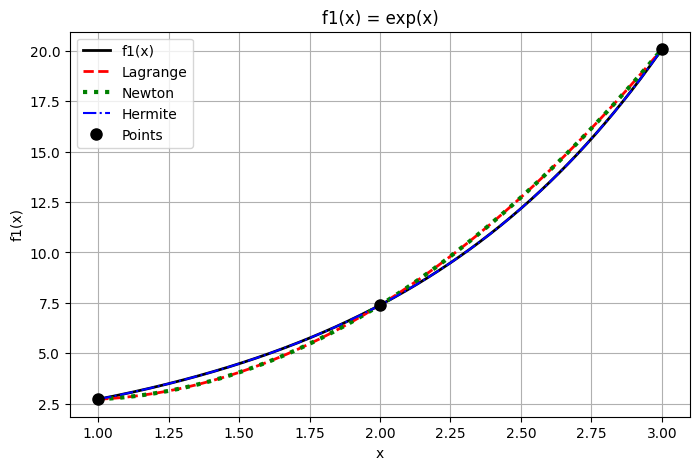

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(x, y_reelle1, "k-", lw=2, label="f1(x)")
plt.plot(x, y_lagrange1, "r--", lw=2, label="Lagrange")
plt.plot(x, y_newton1, "g:", lw=3, label="Newton")
plt.plot(x, y_hermite1, "b-.", lw=1.5, label="Hermite")
plt.plot(x_points, y_points1, "ko", ms=8, label="Points")
plt.title("f1(x) = exp(x)")
plt.xlabel("x")
plt.ylabel("f1(x)")
plt.grid(True)
plt.legend()
plt.show()

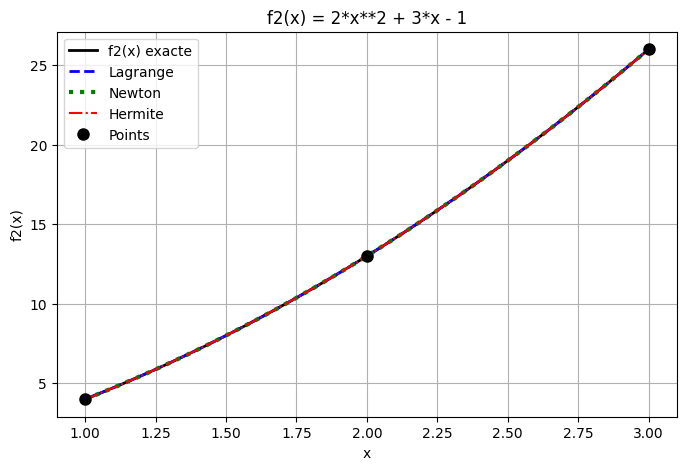

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(x, y_reelle2, "k-", lw=2, label="f2(x) exacte")
plt.plot(x, y_lagrange2, "b--", lw=2, label="Lagrange")
plt.plot(x, y_newton2, "g:", lw=3, label="Newton")
plt.plot(x, y_hermite2, "r-.", lw=1.5, label="Hermite")
plt.plot(x_points, y_points2, "ko", ms=8, label="Points")
plt.title("f2(x) = 2*x**2 + 3*x - 1")
plt.xlabel("x")
plt.ylabel("f2(x)")
plt.grid(True)
plt.legend()
plt.show()

In [27]:
# Nouveaux points
x_points_new = np.array([1, 1.5, 2, 2.5, 3], dtype=float)
# Nouvel intervalle
x_new = np.linspace(1, 3, 500)
y_points1_new = f1(x_points_new)
dy_points1_new = df1(x_points_new)
# Fonction exacte
y_reelle1_new = f1(x_new)
# Lagrange
y_lagrange1_new = np.array([ lagrange(xi, x_points_new, y_points1_new) for xi in x_new])

# Newton
coef1_new = divided_diff(x_points_new, y_points1_new)
y_newton1_new = np.array([ newton(coef1_new, x_points_new, xi) for xi in x_new])

# Hermite
y_hermite1_new = np.array([ hermite(xi, x_points_new, y_points1_new, dy_points1_new) for xi in x_new])

In [ ]:

y_points2_new = f2(x_points_new)
dy_points2_new = df2(x_points_new)

# Fonction exacte
y_reelle2_new = f2(x_new)

# Lagrange
y_lagrange2_new = np.array([
    lagrange(xi, x_points_new, y_points2_new)
    for xi in x_new
])

# Newton
coef2_new = divided_diff(x_points_new, y_points2_new)

y_newton2_new = np.array([
    newton(coef2_new, x_points_new, xi)
    for xi in x_new
])

# Hermite
y_hermite2_new = np.array([
    hermite(xi, x_points_new, y_points2_new, dy_points2_new)
    for xi in x_new
])

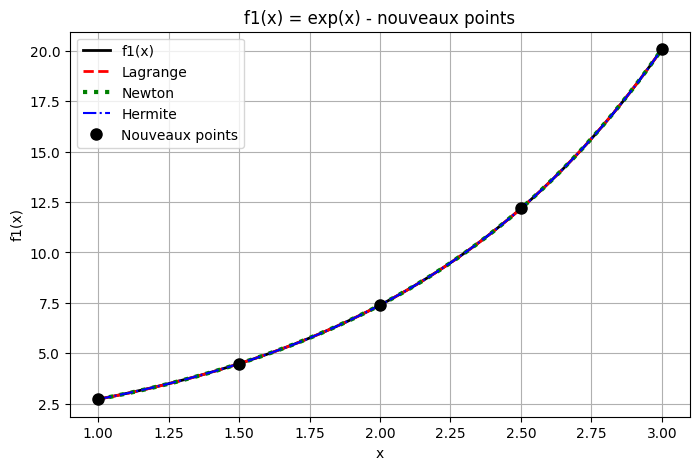

In [29]:
# GRAPHE 3 : f1 avec les nouveaux points

plt.figure(figsize=(8, 5))
plt.plot(x_new, y_reelle1_new, "k-", lw=2, label="f1(x)")
plt.plot(x_new, y_lagrange1_new, "r--", lw=2, label="Lagrange")
plt.plot(x_new, y_newton1_new, "g:", lw=3, label="Newton")
plt.plot(x_new, y_hermite1_new, "b-.", lw=1.5, label="Hermite")
plt.plot( x_points_new, y_points1_new, "ko", ms=8,label="Nouveaux points")
plt.title("f1(x) = exp(x) - nouveaux points")
plt.xlabel("x")
plt.ylabel("f1(x)")
plt.grid(True)
plt.legend()
plt.show()

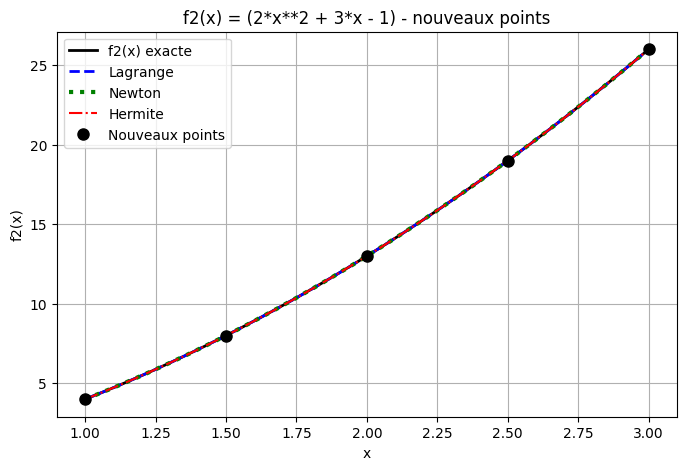

In [31]:
# GRAPHE 4 : f2 avec les nouveaux points
plt.figure(figsize=(8, 5))
plt.plot(x_new, y_reelle2_new, "k-", lw=2, label="f2(x) exacte")
plt.plot(x_new, y_lagrange2_new, "b--", lw=2, label="Lagrange")
plt.plot(x_new, y_newton2_new, "g:", lw=3, label="Newton")
plt.plot(x_new, y_hermite2_new, "r-.", lw=1.5, label="Hermite")
plt.plot( x_points_new,  y_points2_new,"ko", ms=8, label="Nouveaux points")
plt.title("f2(x) = (2*x**2 + 3*x - 1) - nouveaux points")
plt.xlabel("x")
plt.ylabel("f2(x)")
plt.grid(True)
plt.legend()
plt.show()